# Imports

In [1]:
# %matplotlib inline
import os
import stim
import sinter
import matplotlib.pyplot as plt
import pymatching
from typing import List

# Stim's built-in method for 1 round of d=3 surface code, z-memory experiment

- source code in C++: https://github.com/quantumlib/Stim/blob/main/src/stim/gen/gen_surface_code.cc
- The arguments cover stochastic Pauli errors, thus parameters therefore give  a simplified circuit-level Pauli noise model.

In [2]:
# Call function with no error, so that we can compare our no-error circuits to this.

surface_code_circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    rounds=1,
    distance=3,
    after_clifford_depolarization=0.00, # 16 possible 1q and 2q cliffords including identity (imperfect quantum gates).
    after_reset_flip_probability=0.00, # Computational basis quantum bit flip (imperfect state preparation).
    before_measure_flip_probability=0.00, # Classical bit flip (imperfect measurement outcome).
    before_round_data_depolarization=0.00 # Imperfect memory/decoherence between rounds.
) 

In [3]:
print(repr(surface_code_circuit))

stim.Circuit('''
    QUBIT_COORDS(1, 1) 1
    QUBIT_COORDS(2, 0) 2
    QUBIT_COORDS(3, 1) 3
    QUBIT_COORDS(5, 1) 5
    QUBIT_COORDS(1, 3) 8
    QUBIT_COORDS(2, 2) 9
    QUBIT_COORDS(3, 3) 10
    QUBIT_COORDS(4, 2) 11
    QUBIT_COORDS(5, 3) 12
    QUBIT_COORDS(6, 2) 13
    QUBIT_COORDS(0, 4) 14
    QUBIT_COORDS(1, 5) 15
    QUBIT_COORDS(2, 4) 16
    QUBIT_COORDS(3, 5) 17
    QUBIT_COORDS(4, 4) 18
    QUBIT_COORDS(5, 5) 19
    QUBIT_COORDS(4, 6) 25
    R 1 3 5 8 10 12 15 17 19 2 9 11 13 14 16 18 25
    TICK
    H 2 11 16 25
    TICK
    CX 2 3 16 17 11 12 15 14 10 9 19 18
    TICK
    CX 2 1 16 15 11 10 8 14 3 9 12 18
    TICK
    CX 16 10 11 5 25 19 8 9 17 18 12 13
    TICK
    CX 16 8 11 3 25 17 1 9 10 18 5 13
    TICK
    H 2 11 16 25
    TICK
    MR 2 9 11 13 14 16 18 25
    DETECTOR(0, 4, 0) rec[-4]
    DETECTOR(2, 2, 0) rec[-7]
    DETECTOR(4, 4, 0) rec[-2]
    DETECTOR(6, 2, 0) rec[-5]
    M 1 3 5 8 10 12 15 17 19
    DETECTOR(0, 4, 1) rec[-3] rec[-6] rec[-13]
    DETECTOR(2, 2,

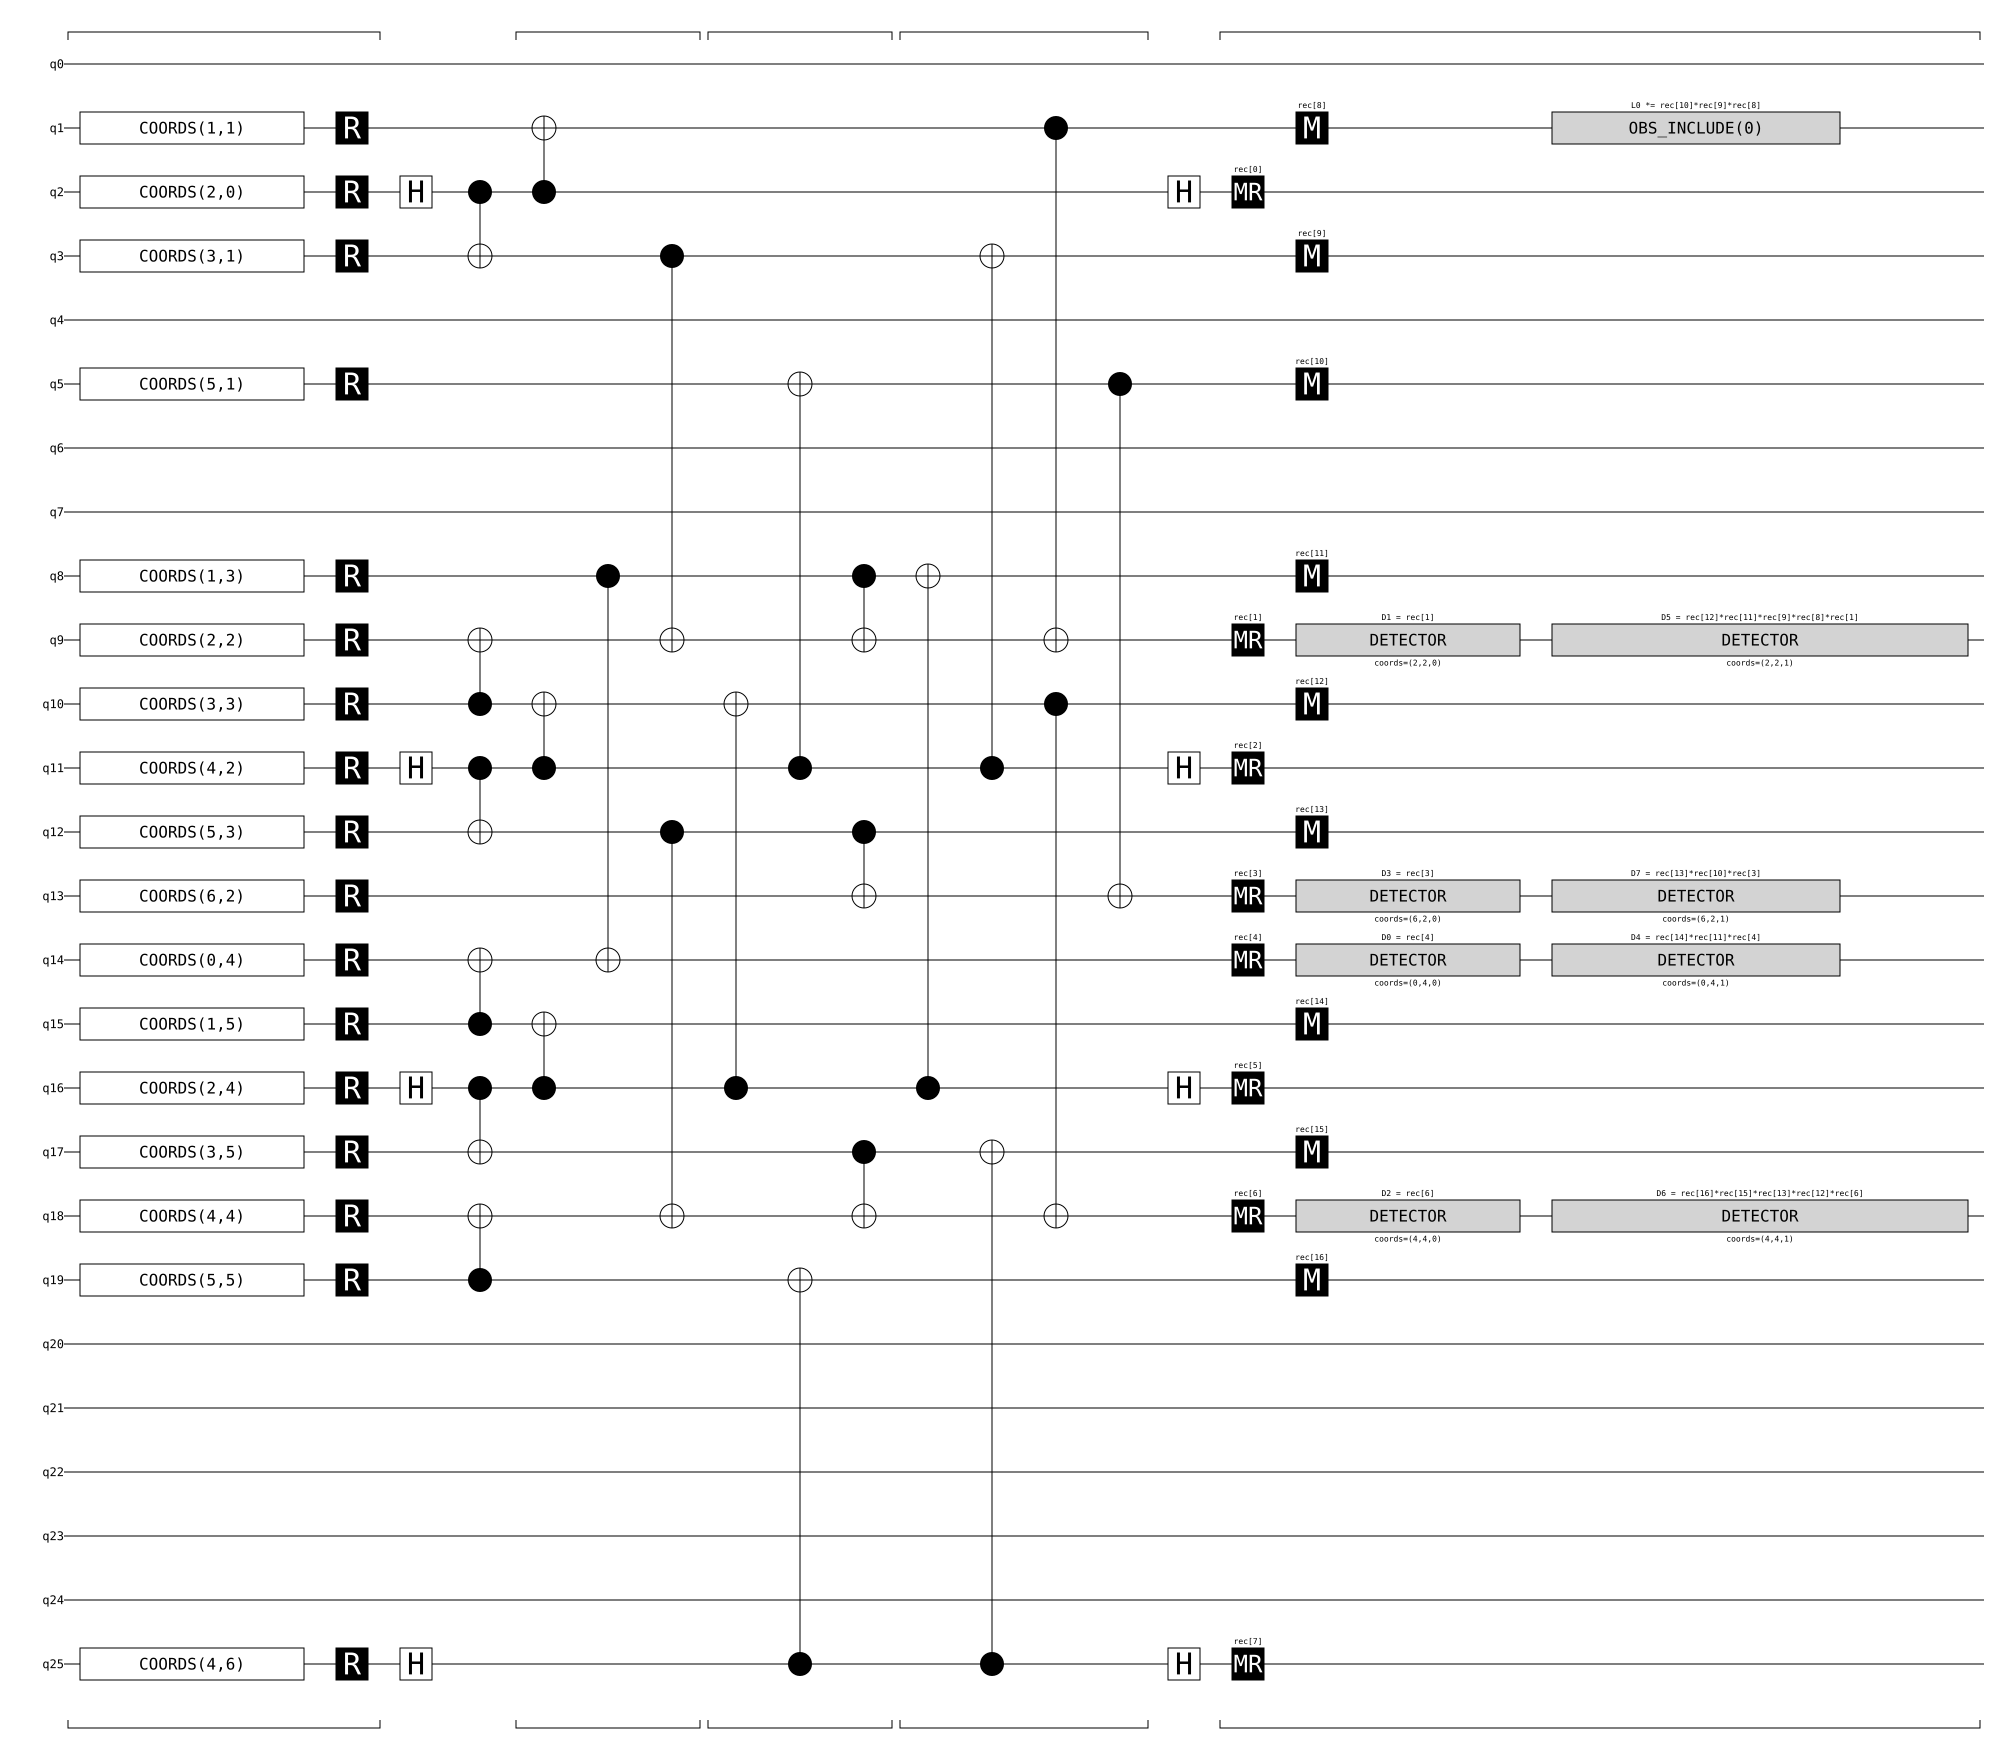

In [4]:
surface_code_circuit.diagram('timeline-svg')

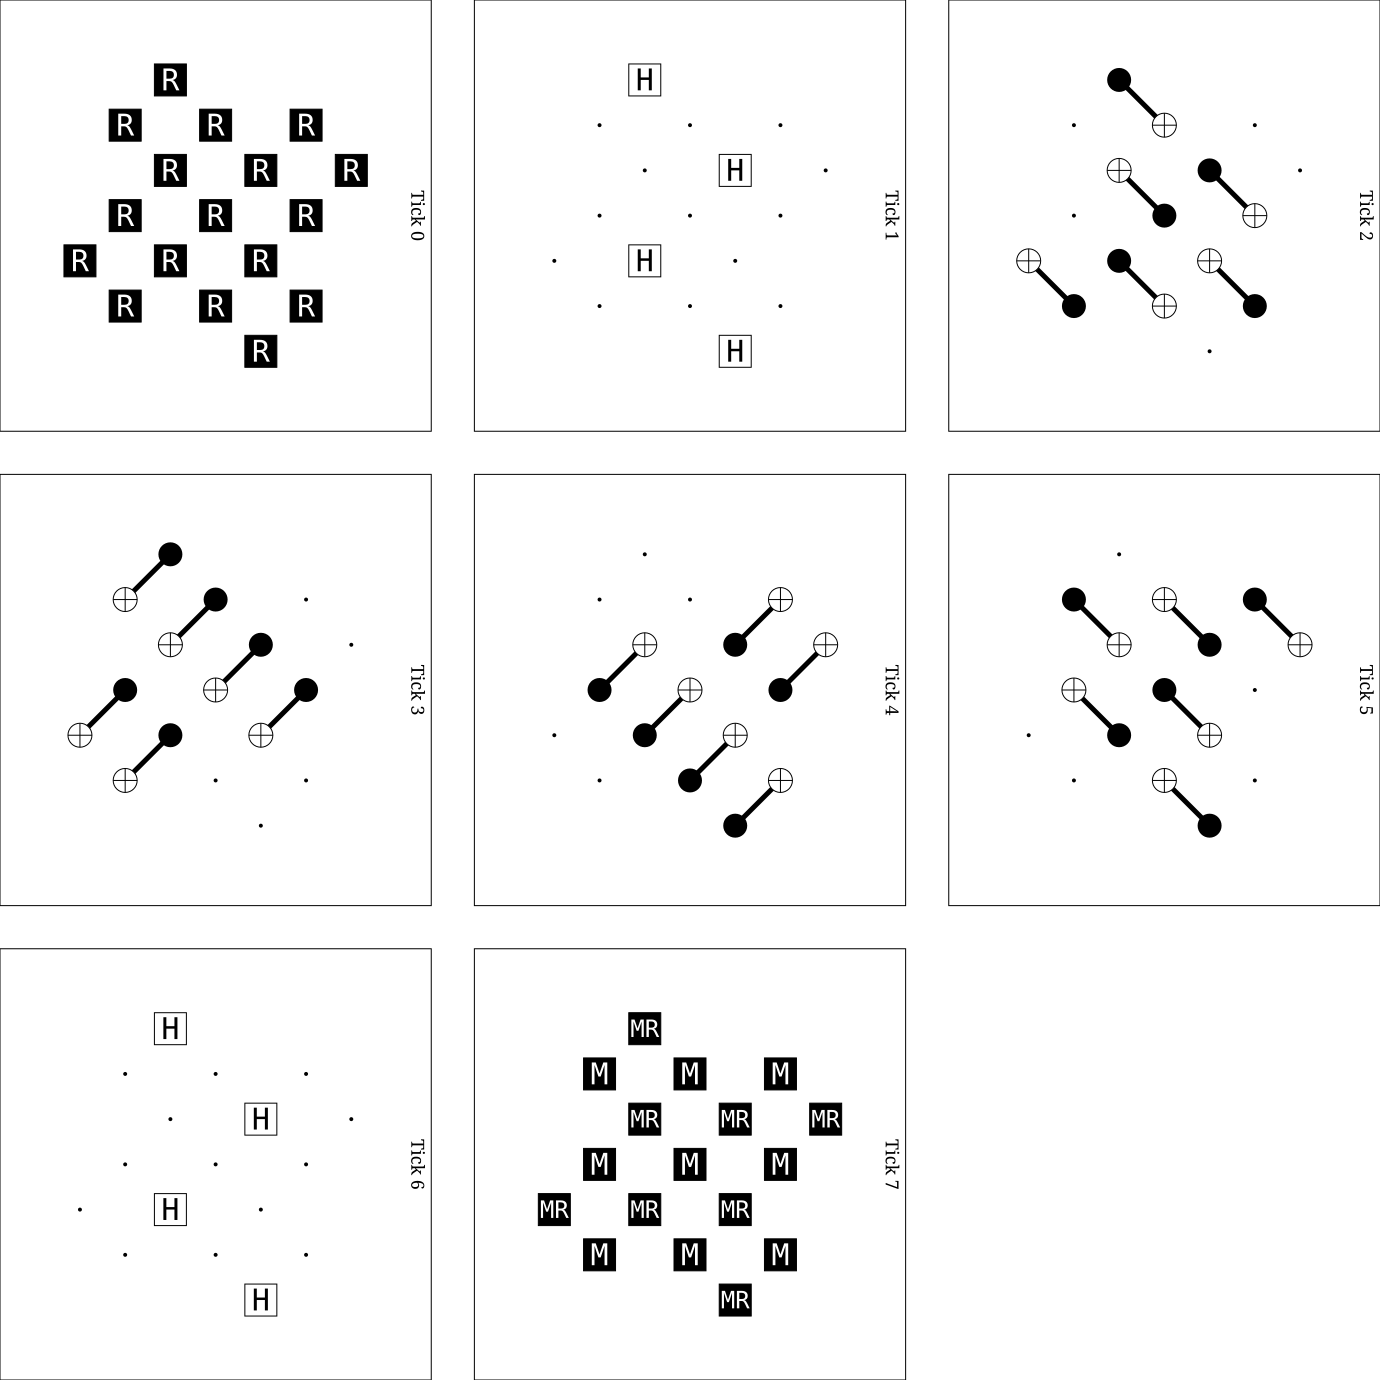

In [5]:
surface_code_circuit.without_noise().diagram("timeslice-svg")

# Manual method for 1 round of d=3 surface code, without noise

- When called, the output should match stim's output.
- see Notability Note explaining each step.

In [6]:
def my_d3_rotated_memory_z():
    
    c = stim.Circuit()

    # ------------------------------------------------------------
    # 1. Qubit layout.
    # ------------------------------------------------------------

    coords = {
        1:  (1, 1), # Qubit index: (x cord, y cord).
        2:  (2, 0),
        3:  (3, 1),
        5:  (5, 1),
        8:  (1, 3),
        9:  (2, 2),
        10: (3, 3),
        11: (4, 2),
        12: (5, 3),
        13: (6, 2),
        14: (0, 4),
        15: (1, 5),
        16: (2, 4),
        17: (3, 5),
        18: (4, 4),
        19: (5, 5),
        25: (4, 6),
    }

    for q, (x, y) in coords.items():
        
        c.append("QUBIT_COORDS", [q], [x, y])

    # 9 data qubits IN THIS ORDER.
    data = [1, 3, 5, 8, 10, 12, 15, 17, 19]

    # 8 stabilizer ancillas IN THIS ORDER.
    ancillas = [2, 9, 11, 13, 14, 16, 18, 25]

    # X-stabilizer ancillas.
    x_ancillas = [2, 11, 16, 25]

    # ------------------------------------------------------------
    # 2. Initialize all physical qubits in |0>.
    # ------------------------------------------------------------

    # Z-basis reset of all data and ancilla qubits.
    c.append("R", data + ancillas)

    # ------------------------------------------------------------
    # 3. One stabilizer measurement round.
    # ------------------------------------------------------------

    c.append("TICK")

    # Turn X-check ancillas into |+>.
    c.append("H", x_ancillas)

    # Four CNOT layers.
    # For X checks: (control) ancilla -> data (target).
    # For Z checks: (control) data -> ancilla (target).
    # The chosen schedule ensures no qubit participates in more than 1 gate simultaneously,
    # that there aren't unwanted interactions between adjacent ancillae,
    # and hook errors don't reduce effective code distance.
    # The chosen schedule is also chosen to match that output from Stim.
    # See the handwritten Notability note for more details.

    c.append("TICK")
    c.append("CX", [
        2, 3,
        16, 17,
        11, 12,
        15, 14,
        10, 9,
        19, 18,
    ])

    c.append("TICK")
    c.append("CX", [
        2, 1,
        16, 15,
        11, 10,
        8, 14,
        3, 9,
        12, 18,
    ])

    c.append("TICK")
    c.append("CX", [
        16, 10,
        11, 5,
        25, 19,
        8, 9,
        17, 18,
        12, 13,
    ])

    c.append("TICK")
    c.append("CX", [
        16, 8,
        11, 3,
        25, 17,
        1, 9,
        10, 18,
        5, 13,
    ])

    # Rotate X-check ancillas back from X into Z basis.
    c.append("TICK")
    c.append("H", x_ancillas)

    # Measure and reset all stabilizer ancillas.
    c.append("TICK")
    c.append("MR", ancillas)

    # ------------------------------------------------------------
    # 4. Detectors after the first syndrome round (Check Z stabilizers, whose values are initially known).
    # ------------------------------------------------------------
    #
    # Because we initialized in logical Z, the Z stabilizers have
    # known +1 values immediately. The X stabilizers do not.
    #
    # MR order:
    #   q2 q9 q11 q13 q14 q16 q18 q25
    #   -8 -7 -6  -5  -4  -3  -2  -1

    c.append(
        "DETECTOR",
        [stim.target_rec(-4)],
        [0, 4, 0],
    )  # Z check q14

    c.append(
        "DETECTOR",
        [stim.target_rec(-7)],
        [2, 2, 0],
    )  # Z check q9

    c.append(
        "DETECTOR",
        [stim.target_rec(-2)],
        [4, 4, 0],
    )  # Z check q18

    c.append(
        "DETECTOR",
        [stim.target_rec(-5)],
        [6, 2, 0],
    )  # Z check q13

    # ------------------------------------------------------------
    # 5. Z-basis measurement of the data.
    # ------------------------------------------------------------

    c.append("M", data)

    # ------------------------------------------------------------
    # 6. Time-boundary detectors.
    # ------------------------------------------------------------
    #
    # Compare the above Z measurements on data qubits against the
    # appropriate Z-stabilizer measurements on ancilla.

    # Boundary Z stabilizer.
    c.append(
        "DETECTOR",
        [
            stim.target_rec(-3), # Final q15 meas.
            stim.target_rec(-6), # Final q8 meas.
            stim.target_rec(-13), # Last a14 meas.
        ],
        [0, 4, 1], # a14 has x=0, y=4, and annotate t=1 
                   # to help distinguish between final measurement boundary from syndrome measurements.
    )

    # Bulk Z stabilizer.
    c.append(
        "DETECTOR",
        [
            stim.target_rec(-5),
            stim.target_rec(-6),
            stim.target_rec(-8),
            stim.target_rec(-9),
            stim.target_rec(-16),
        ],
        [2, 2, 1],
    )

    # Boundary Z stabilizer.
    c.append(
        "DETECTOR",
        [
            stim.target_rec(-1),
            stim.target_rec(-2),
            stim.target_rec(-4),
            stim.target_rec(-5),
            stim.target_rec(-11),
        ],
        [4, 4, 1],
    )

    # Bulk Z stabilizer.
    c.append(
        "DETECTOR",
        [
            stim.target_rec(-4),
            stim.target_rec(-7),
            stim.target_rec(-14),
        ],
        [6, 2, 1],
    )

    # ------------------------------------------------------------
    # 7. Logical Z measurement
    # ------------------------------------------------------------
    #
    # Top row q1-q3-q5 is one representative of logical Z. WLOG we pick this.
    #
    # Final data measurements were, in this order:
    # q1 q3 q5 q8 q10 q12 q15 q17 q19
    #
    # Therefore, q1,q3,q5 are rec[-9], rec[-8], rec[-7].

    c.append(
        "OBSERVABLE_INCLUDE",
        [
            stim.target_rec(-7),
            stim.target_rec(-8),
            stim.target_rec(-9),
        ],
        0, # Logical observable index. Here we only have 1 logial qubit, and measured in Z, so one logical observable.
    )

    return c

In [7]:
# Check if manual and stim circuits match, by directly comparing the output strings.

mine = my_d3_rotated_memory_z()

stim_version = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=3,
    rounds=1,
)

print("Mine:")
print(mine)

print("\nStim:")
print(stim_version)

print("\nExact match:", mine == stim_version)

Mine:
QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19 2 9 11 13 14 16 18 25
TICK
H 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
TICK
MR 2 9 11 13 14 16 18 25
DETECTOR(0, 4, 0) rec[-4]
DETECTOR(2, 2, 0) rec[-7]
DETECTOR(4, 4, 0) rec[-2]
DETECTOR(6, 2, 0) rec[-5]
M 1 3 5 8 10 12 15 17 19
DETECTOR(0, 4, 1) rec[-3] rec[-6] rec[-13]
DETECTOR(2, 2, 1) rec[-5] rec[-6] rec[-8] rec[-9] rec[-16]
DETECTOR(4, 4, 1) rec[-1] rec[-2] rec[-4] rec[-5] rec[-11]
DETECTOR(6, 2, 1) rec[-4] rec[-7] rec[-14]
OBSERVABLE_INCLUDE(0

# Manual method for at least 2 rounds of d=3 surface code with code-capacity error model

- Single instance of depolarizing error inserted on data qubits after 1st round.
- Thus, needs at least two rounds.

In [8]:
def my_d3_rotated_memory_z(rounds=2, p=0.0):

    # Only allow 2 rounds or more.
    
    if rounds < 2:
        
        raise ValueError("Need at least two rounds to measure errors inserted after the first round")
    
    c = stim.Circuit()

    # ------------------------------------------------------------
    # 1. Qubit layout.
    # ------------------------------------------------------------

    coords = {
        1:  (1, 1),
        2:  (2, 0),
        3:  (3, 1),
        5:  (5, 1),
        8:  (1, 3),
        9:  (2, 2),
        10: (3, 3),
        11: (4, 2),
        12: (5, 3),
        13: (6, 2),
        14: (0, 4),
        15: (1, 5),
        16: (2, 4),
        17: (3, 5),
        18: (4, 4),
        19: (5, 5),
        25: (4, 6),
    }

    for q, (x, y) in coords.items():
        
        c.append("QUBIT_COORDS", [q], [x, y])

    # 9 data qubits IN THIS ORDER
    data = [1, 3, 5, 8, 10, 12, 15, 17, 19]

    # 8 stabilizer ancillas IN THIS ORDER
    ancillas = [2, 9, 11, 13, 14, 16, 18, 25]

    # X-stabilizer ancillas
    x_ancillas = [2, 11, 16, 25]

    # ------------------------------------------------------------
    # 2. Initialize all physical qubits in |0>.
    # ------------------------------------------------------------

    # Z-basis reset of all data and ancilla qubits.
    c.append("R", data + ancillas)

    # ------------------------------------------------------------
    # 3. Repeated stabilizer measurement rounds.
    # ------------------------------------------------------------

    for r in range(rounds):

        c.append("TICK")
        c.append("H", x_ancillas)

        c.append("TICK")
        c.append("CX", [
            2, 3,
            16, 17,
            11, 12,
            15, 14,
            10, 9,
            19, 18,
        ])

        c.append("TICK")
        c.append("CX", [
            2, 1,
            16, 15,
            11, 10,
            8, 14,
            3, 9,
            12, 18,
        ])

        c.append("TICK")
        c.append("CX", [
            16, 10,
            11, 5,
            25, 19,
            8, 9,
            17, 18,
            12, 13,
        ])

        c.append("TICK")
        c.append("CX", [
            16, 8,
            11, 3,
            25, 17,
            1, 9,
            10, 18,
            5, 13,
        ])

        c.append("TICK")
        c.append("H", x_ancillas)

        c.append("TICK")
        c.append("MR", ancillas)

        # --------------------------------------------------------
        # 4. Detectors.
        # --------------------------------------------------------

        if r == 0:
            
            # First round: deterministic Z checks.
            
            for q in [14, 9, 18, 13]:
                i = ancillas.index(q)
                x, y = coords[q]

                c.append(
                    
                    "DETECTOR",
                    [stim.target_rec(i - 8)],
                    [x, y, r],
                )

            # CODE CAPACITY ERROR MODEL. 
            # Apply one noise instance to DATA qubits after preparation
            # (assumes syndrome extraction is perfect, so no error on ANCILLA).
            # This only occurs once in the whole experiment, since it is inside this r==0 branch.
            
            c.append("TICK")
            c.append("DEPOLARIZE1", data, p)

        else:
            
            # Later rounds: compare consecutive syndromes for BOTH X AND Z checks.
            # Although the first X-stabilizer measurement is random, 
            # it projects the state into a definite eigenstate of that stabilizer.
            # First round: Z checks can be compared against their known initial values.
            # Later rounds: Both X and Z checks can be compared against their previous values.
            
            for i, q in enumerate(ancillas):
                
                x, y = coords[q]

                c.append(
                    
                    "DETECTOR",
                    [
                        # Compare current round's and previous round's measurements.
                        stim.target_rec(i - 8), # Current round.
                        stim.target_rec(i - 16), # Previous round.
                    ],
                    [x, y, r],
                )

    # ------------------------------------------------------------
    # 5. Final Z-basis measurement of the data.
    # ------------------------------------------------------------

    c.append("M", data)

    # ------------------------------------------------------------
    # 6. Final boundary detectors.
    # ------------------------------------------------------------

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-3),
            stim.target_rec(-6),
            stim.target_rec(-13),
        ],
        [0, 4, rounds],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-5),
            stim.target_rec(-6),
            stim.target_rec(-8),
            stim.target_rec(-9),
            stim.target_rec(-16),
        ],
        [2, 2, rounds],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-1),
            stim.target_rec(-2),
            stim.target_rec(-4),
            stim.target_rec(-5),
            stim.target_rec(-11),
        ],
        [4, 4, rounds],
    )

    c.append(
        "DETECTOR",
        [
            stim.target_rec(-4),
            stim.target_rec(-7),
            stim.target_rec(-14),
        ],
        [6, 2, rounds],
    )

    # ------------------------------------------------------------
    # 7. Logical Z measurement.
    # ------------------------------------------------------------
    #
    # Top row q1-q3-q5 is one representative of logical Z.
    #
    # Final data measurements were, in this order:
    # q1 q3 q5 q8 q10 q12 q15 q17 q19
    #
    # Therefore, q1,q3,q5 are rec[-9], rec[-8], rec[-7].

    c.append(
        "OBSERVABLE_INCLUDE",
        [
            stim.target_rec(-7),
            stim.target_rec(-8),
            stim.target_rec(-9),
        ],
        0,
    )

    return c

In [9]:
# Verify the above code by calling manual functions with 3 rounds,
# then confirming number of detectors is what we expect. 

mine = my_d3_rotated_memory_z(rounds=3, 
                              p=0.01)


# for d = 3, expect 4+8*(3-1)+4 = 24. 
# (I.e. at temporal boundaries, only Z detectors available. 
# in bulk, which occurs for 3-1=2 rounds, both Z and X detector available).
print("Detectors:", mine.num_detectors) 

print("Observables:", mine.num_observables) 
print("\n")

print("code DEM:")
print(mine.detector_error_model(decompose_errors=True))

Detectors: 24
Observables: 1


code DEM:
error(0.003344519141621982) D4
error(0.003344519141621982) D4 D6
error(0.003344519141621982) D4 D6 ^ D5 L0
error(0.003344519141621982) D4 ^ D5 L0
error(0.003344519141621982) D5 D8
error(0.003344519141621982) D5 D8 ^ D9
error(0.003344519141621982) D5 D10
error(0.003344519141621982) D5 D10 ^ D6 D9
error(0.006666666666666613) D5 L0
error(0.006666666666666613) D6
error(0.003344519141621982) D6 D9
error(0.003344519141621982) D6 ^ D7 L0
error(0.003344519141621982) D7 D10
error(0.003344519141621982) D7 D10 ^ D6
error(0.003344519141621982) D7 L0
error(0.003344519141621982) D8
error(0.006666666666666613) D9
error(0.003344519141621982) D9 D11
error(0.003344519141621982) D9 D11 ^ D10
error(0.003344519141621982) D9 ^ D8
error(0.006666666666666613) D10
error(0.003344519141621982) D11
error(0.003344519141621982) D11 ^ D10
detector(0, 4, 0) D0
detector(2, 2, 0) D1
detector(4, 4, 0) D2
detector(6, 2, 0) D3
detector(2, 0, 1) D4
detector(2, 2, 1) D5
detector(4, 2

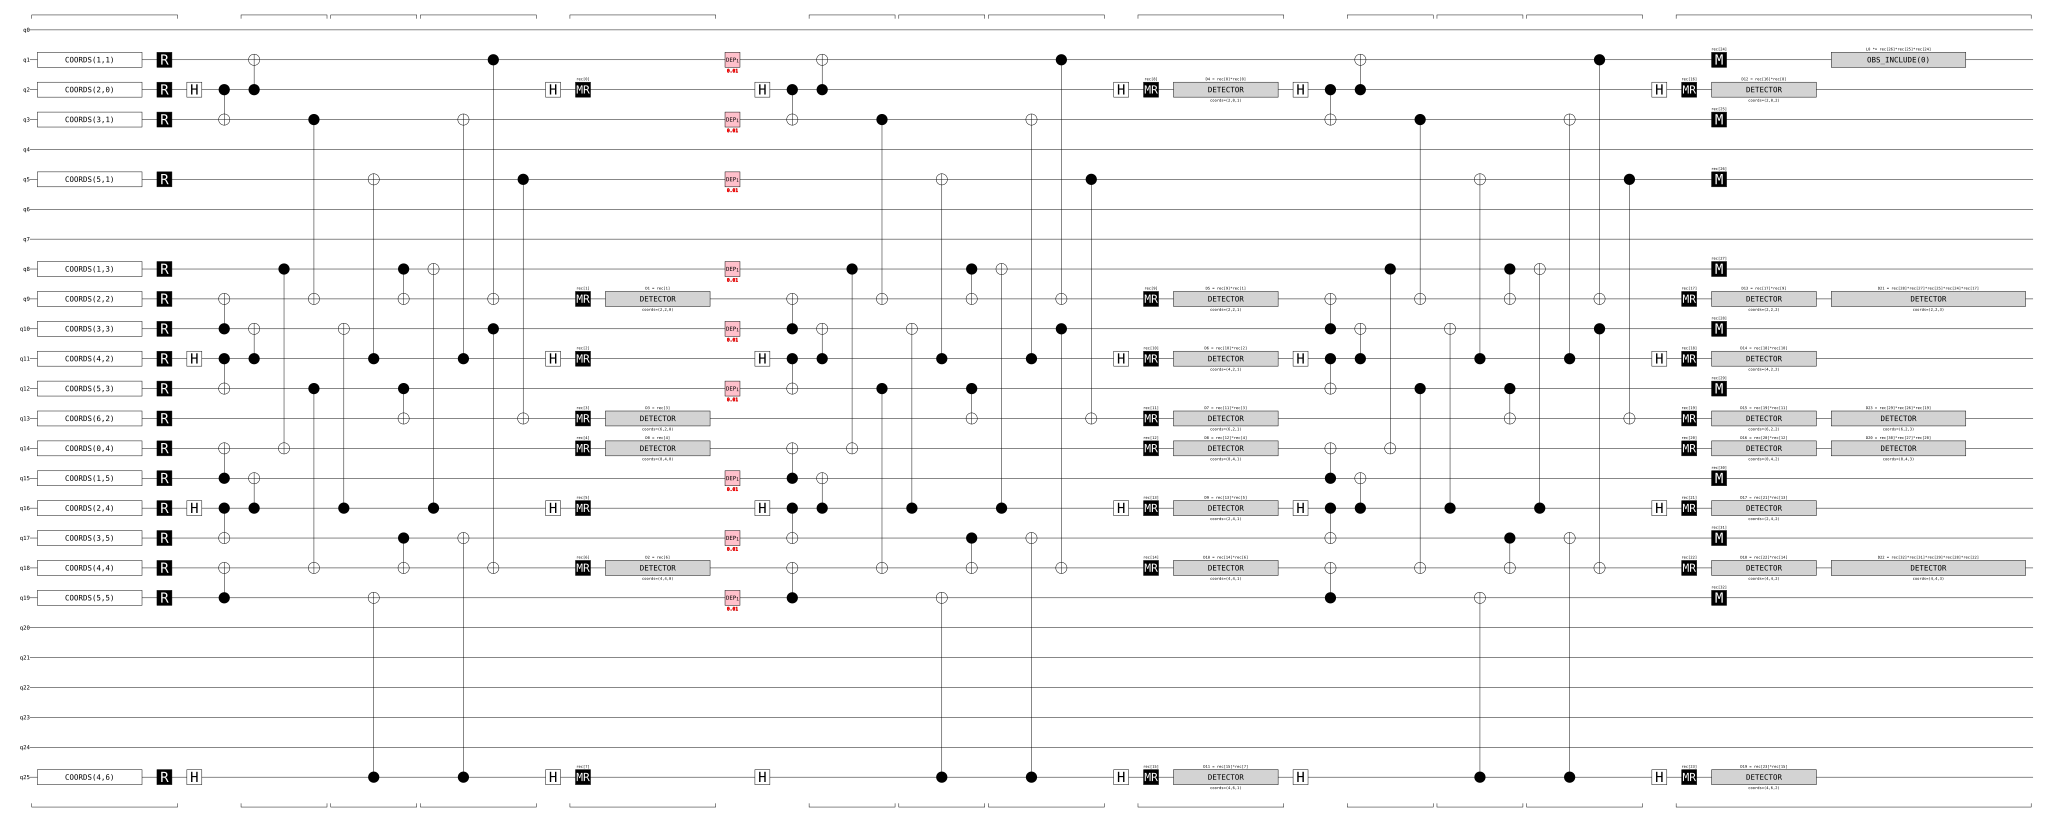

In [10]:
display(mine.diagram("timeline-svg"))

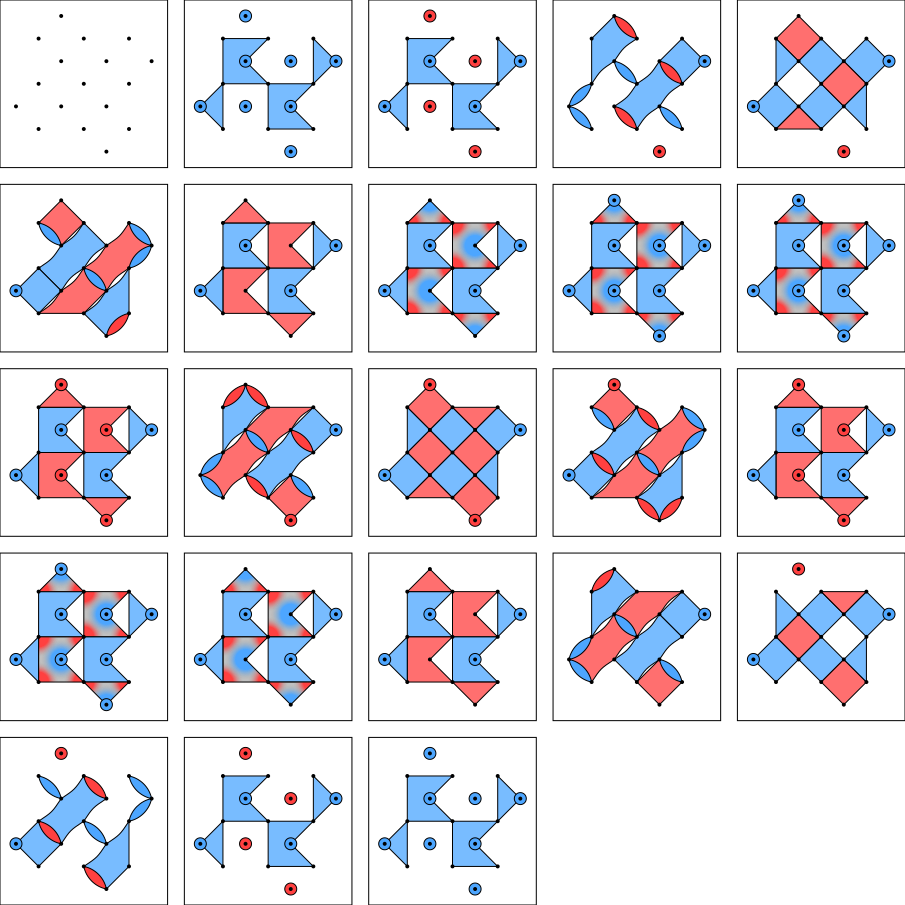

In [11]:
display(mine.diagram("detector-slice-svg"))

In [12]:
display(mine.diagram("matchgraph-3d"))

# Nodes = detectors.
# Edges = possible faults.
# Red edges = possible faults that can flip logical observable.

{"accessors":[{"bufferView":0,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":1,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":2,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":3,"byteOffset":0,"componentType":5126,"count":9,"max":[0,0.400000005960464,0.400000005960464],"min":[0,-0.400000005960464,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":4,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0,0.400000005960464],"min":[-0.400000005960464,0,-0.400000005960464],"name":"circle_loop","type":"VEC3"},{"bufferView":5,"byteOffset":0,"componentType":5126,"count":9,"max":[0.400000005960464,0.400000005960464,0],"min":[-0.400000005960464,-0.400000005960464,0],"name":"circle_loop","type":"VEC3"},{"bufferView":6,"byteOffset":0,"componentType":5126,"count":54,"max":[18.6666679382324,27.3704261779785,3],"min":[-9.3704252243042,-9.3704252243042,-0.333333492279053],"name":"buf_scattered_lines","type":"VEC3"},{"bufferView":7,"byteOffset":0,"componentType":5126,"count":10,"max":[27.3704261779785,6,3],"min":[-0.666666984558105,-0.666666984558105,-0.333333492279053],"name":"buf_red_scattered_lines","type":"VEC3"}],"asset":{"version":"2.0"},"bufferViews":[{"buffer":0,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":1,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":2,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":3,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":4,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":5,"byteLength":108,"byteOffset":0,"name":"circle_loop","target":34962},{"buffer":6,"byteLength":648,"byteOffset":0,"name":"buf_scattered_lines","target":34962},{"buffer":7,"byteLength":120,"byteOffset":0,"name":"buf_red_scattered_lines","target":34962}],"buffers":[{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAM3MzD4AAAAAAAAAAMPQkD7D0JA+AAAAAPIwlrLNzMw+AAAAAMPQkL7D0JA+AAAAAM3MzL7yMBazAAAAAMHQkL7E0JC+AAAAAPLkozHNzMy+AAAAAMbQkD6/0JC+AAAAAM3MzD4AAAAA"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,AAAAAAAAAADNzMw+w9CQPgAAAADD0JA+zczMPgAAAADyMJayw9CQPgAAAADD0JC+8jAWswAAAADNzMy+xNCQvgAAAADB0JC+zczMvgAAAADy5KMxv9CQvgAAAADG0JA+AAAAAAAAAADNzMw+"},{"byteLength":108,"name":"circle_loop","uri":"data:application/octet-stream;base64,zczMPgAAAAAAAAAAw9CQPsPQkD4AAAAA8jCWss3MzD4AAAAAw9CQvsPQkD4AAAAAzczMvvIwFrMAAAAAwdCQvsTQkL4AAAAA8uSjMc3MzL4AAAAAxtCQPr/QkL4AAAAAzczMPgAAAAAAAAAA"},{"byteLength":648,"name":"buf_scattered_lines","uri":"data:application/octet-stream;base64,AADAQAAAAAAAAEBA/Bg4QEPtFcH8GLg/AADAQAAAAAAAAEBAAABAQQAAwEAAAEBAAADAQAAAAAAAAEBAAABAQQAAwEAAAEBAAADAQAAAAAAAAEBA/Bg4QEPtFcH8GLg/AADAQAAAwEAAAEBAAAAAAAAAQEEAAEBAAADAQAAAwEAAAEBAAAAAAAAAQEEAAEBAAADAQAAAQEEAAEBAsKoqv1ZVlUGwqqq+

In [13]:
# decompose_errors=True asks Stim to decompose complex error mechanisms into graphlike components, 
# ideally involving at most two detectors each.
# This representation helps matching decoders interpret correlated faults using a graph.
# Stim uses two decomposition strategies, in order: Intra-channel decomposition, and Inter-channel decomposition.

dem = mine.detector_error_model(decompose_errors=True)

for instruction in dem:
    print(instruction)

# Example output:
# 'error(0.00334452) D4' = with probability 0.00334452, detector 4 fires.
# 'error(0.00334452) D4 D6 ^ D5 L0' = with probability 0.00334452, D4 D6 D5 fires and L0 flps.

error(0.00334452) D4
error(0.00334452) D4 D6
error(0.00334452) D4 D6 ^ D5 L0
error(0.00334452) D4 ^ D5 L0
error(0.00334452) D5 D8
error(0.00334452) D5 D8 ^ D9
error(0.00334452) D5 D10
error(0.00334452) D5 D10 ^ D6 D9
error(0.00666667) D5 L0
error(0.00666667) D6
error(0.00334452) D6 D9
error(0.00334452) D6 ^ D7 L0
error(0.00334452) D7 D10
error(0.00334452) D7 D10 ^ D6
error(0.00334452) D7 L0
error(0.00334452) D8
error(0.00666667) D9
error(0.00334452) D9 D11
error(0.00334452) D9 D11 ^ D10
error(0.00334452) D9 ^ D8
error(0.00666667) D10
error(0.00334452) D11
error(0.00334452) D11 ^ D10
detector(0, 4, 0) D0
detector(2, 2, 0) D1
detector(4, 4, 0) D2
detector(6, 2, 0) D3
detector(2, 0, 1) D4
detector(2, 2, 1) D5
detector(4, 2, 1) D6
detector(6, 2, 1) D7
detector(0, 4, 1) D8
detector(2, 4, 1) D9
detector(4, 4, 1) D10
detector(4, 6, 1) D11
detector(2, 0, 2) D12
detector(2, 2, 2) D13
detector(4, 2, 2) D14
detector(6, 2, 2) D15
detector(0, 4, 2) D16
detector(2, 4, 2) D17
detector(4, 4, 2) D18
de

# Monte Carlo simulation for the manual function

- Monte Carlo simulation of distance-3 surface-code memory experiment at different physical error probabilities, use PyMatching to decode the syndromes, and plot the resulting logical error rates.

Starting 12 workers...
11 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        1 pymatching   ?    1000000        5000 d=3,p=0.01   
        1 pymatching   ?    1000000        5000 d=3,p=0.02   
        1 pymatching   ?    1000000        5000 d=3,p=0.03   
        1 pymatching <1m     965935        4635 d=3,p=0.04   
        1 pymatching   ?    1000000        5000 d=3,p=0.05   
        1 pymatching   ?    1000000        5000 d=3,p=0.06   
        1 pymatching   ?    1000000        5000 d=3,p=0.08   
        1 pymatching   ?    1000000        5000 d=3,p=0.1    
        1 pymatching   ?    1000000        5000 d=3,p=0.12   
        1 pymatching   ?    1000000        5000 d=3,p=0.15   
        2 pymatching   ?    1000000        5000 d=3,p=0.2    
2 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        6 pymatching <1m       5033        4200 d=3,p=0.01   
        6 pymatching <1m      24091        2075 d=3,p=0.02   
0 tasks left:



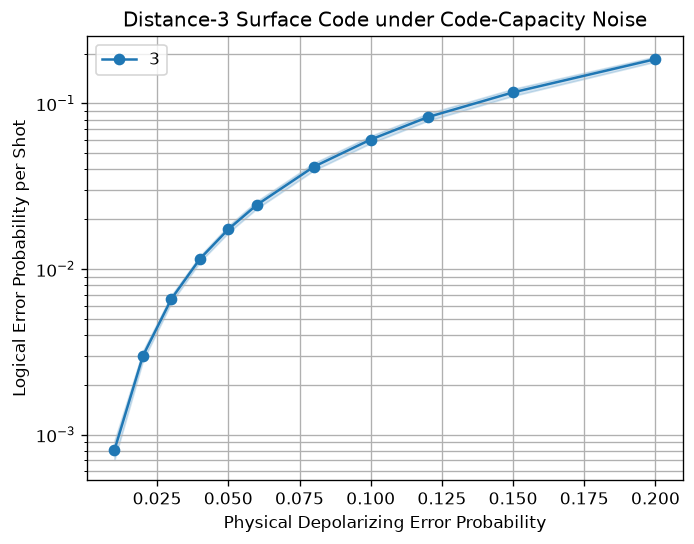

In [14]:
# Create 11 simulation tasks corresponding to different noise levels.

surface_code_tasks = [
    
    sinter.Task(
        circuit=my_d3_rotated_memory_z(rounds=2, 
                                       p=noise), # Pass in the manual function with 2 rounds.
        json_metadata={'d': 3, 'p': noise}, # For identifying & plotting data later.
    )
    for noise in [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10, 0.12, 0.15, 0.20]
]

# Collect statistics.

# 'collected_surface_code_stats: List[sinter.TaskStats]' is a type annotation.

collected_surface_code_stats: List[sinter.TaskStats] = sinter.collect(
    num_workers=os.cpu_count(), # Use approximately one worker per available CPU core.
    tasks=surface_code_tasks, # Run the 11 specified simulation tasks.
    decoders=['pymatching'], # use PyMatching.
    max_shots=1_000_000, # At most one million Monte Carlo samples per task. 
    max_errors=5_000, # Stop each task once approximately 5,000 decoding failures have been observed.
    print_progress=True,
)

# Plot.
fig, ax = plt.subplots(1, 1)

sinter.plot_error_rate(
    ax=ax,
    stats=collected_surface_code_stats,
    x_func=lambda stat: stat.json_metadata['p'], # Determines the horizontal coordinate for each result.
    group_func=lambda stat: stat.json_metadata['d'], # Groups statistics by code distance.
)

ax.set_title("Distance-3 Surface Code under Code-Capacity Noise")
ax.set_xlabel("Physical Depolarizing Error Probability")
ax.set_ylabel("Logical Error Probability per Shot")
ax.set_yscale("log")
ax.grid(which='major')
ax.grid(which='minor')
ax.legend()
fig.set_dpi(120)

plt.show()

# Generalize the manual function to arbitrary odd & even distance.

In [17]:
def my_rotated_memory_z(distance=3, p=0.0, rounds=2):
    
    """
    Generate a rotated surface-code Z-memory circuit with ideal syndrome extraction 
    and one layer of data depolarizing noise after the first syndrome round.
    """

    # Input validation.
    
    if distance < 2:
        raise ValueError('distance must be an integer >= 2')
        
    if rounds < 2:
        raise ValueError('Need a preparation round and a post-noise syndrome round')

    d = distance
    c = stim.Circuit()

    # ------------------------------------------------------------
    # 1. Qubit layout.
    # ------------------------------------------------------------
    # Data qubits have odd/odd coordinates. 
    # Ancilla qubits have even/even coordinates.
    
    data_xy = [(2*x+1, 2*y+1) for y in range(d) for x in range(d)]
    checks = []  # (x, y, Pauli type)

    # Four-body bulk checks, with alternating X and Z types.
    
    for y in range(1, d):
        
        for x in range(1, d):
            
            checks.append((2*x, 2*y, 'Z' if (x+y)%2 == 0 else 'X'))

    # Two-body boundary checks.
    # Add where only two neighboring data qubits exist.
    # Boundary placement depends on whether d is odd or even to preserve
    # commutation between neighboring X and Z stabilizers.
    
    for x in range(1, d):
        
        if x % 2 == 1:
            checks.append((2*x, 0, 'X'))
        if x % 2 != d % 2:
            checks.append((2*x, 2*d, 'X'))

    for y in range(1, d):
        
        if y % 2 == 0:
            checks.append((0, 2*y, 'Z'))
        if y % 2 == d % 2:
            checks.append((2*d, 2*y, 'Z'))

    # Sort the checks in-place spatially, making their indexing deterministic.
    checks.sort(key=lambda t: (t[1], t[0])) 

    # Map spatial coordinates to Stim qubit indices.
    coord_to_q = {} 
    
    for q, xy in enumerate(data_xy + [(x,y) for x,y,_ in checks]):
        
        coord_to_q[xy] = q
        c.append('QUBIT_COORDS', [q], list(xy))

    # Collect the relevant qubits or indices for subsequent instructions.
    
    data = [coord_to_q[xy] for xy in data_xy]
    ancillas = [coord_to_q[(x,y)] for x,y,_ in checks]
    x_ancillas = [coord_to_q[(x,y)] for x,y,t in checks if t == 'X']
    z_check_indices = [i for i,(_,_,t) in enumerate(checks) if t == 'Z']

    # CNOT scheduling.
    # Each (dx,dy) is a diagonal data position relative to the check center.

    x_order = [(1,1), (-1,1), (1,-1), (-1,-1)]
    z_order = [(1,1), (1,-1), (-1,1), (-1,-1)]
    layers = [[] for _ in range(4)]
    
    for x,y,t in checks:
        
        a = coord_to_q[(x,y)]
        
        for k,(dx,dy) in enumerate(x_order if t=='X' else z_order):
            
            q = coord_to_q.get((x+dx, y+dy))
            
            if q is not None:
                
                layers[k].extend([a,q] if t=='X' else [q,a])
                
    # ------------------------------------------------------------
    # 2. Initialize all physical qubits in |0>.
    # ------------------------------------------------------------
    c.append('R', data + ancillas)

    # ------------------------------------------------------------
    # 3. Repeated stabilizer measurement rounds.
    # ------------------------------------------------------------
    n = len(ancillas)
    for r in range(rounds):
        
        c.append('TICK')
        c.append('H', x_ancillas)
        
        for layer in layers:
            
            c.append('TICK')
            
            if layer:
                c.append('CX', layer)
                
        c.append('TICK')
        c.append('H', x_ancillas)
        c.append('TICK')
        c.append('MR', ancillas)

        # --------------------------------------------------------
        # 4. Detectors.
        # --------------------------------------------------------

        if r == 0:
            
            for i in z_check_indices:
                
                x,y,_ = checks[i]
                c.append('DETECTOR', [stim.target_rec(i-n)], [x,y,0])
                
            # Exactly one physical noise instance, after ideal state preparation.
            c.append('TICK')
            c.append('DEPOLARIZE1', data, p)
            
        else:
            
            for i,(x,y,_) in enumerate(checks):
                
                c.append('DETECTOR', [stim.target_rec(i-n),
                                      stim.target_rec(i-2*n)], [x,y,r])

    c.append('TICK')

    # ------------------------------------------------------------
    # 5. Final Z-basis measurement of the data.
    # ------------------------------------------------------------
    
    c.append('M', data)

    # ------------------------------------------------------------
    # 6. Final boundary detectors.
    # ------------------------------------------------------------
    
    data_i = {xy:i for i,xy in enumerate(data_xy)}
    
    for i in z_check_indices:
        
        x,y,_ = checks[i]
        parity = [stim.target_rec(data_i[(x+dx,y+dy)]-len(data))
                  for dx in (-1,1) 
                  for dy in (-1,1)
                  if (x+dx,y+dy) in data_i]
        
        parity.append(stim.target_rec(i-n-len(data)))
        c.append('DETECTOR', parity, [x,y,rounds])

    # ------------------------------------------------------------
    # 7. Logical Z measurement.
    # ------------------------------------------------------------
    c.append('OBSERVABLE_INCLUDE',
             [stim.target_rec(data_i[(2*x+1,1)]-len(data)) for x in range(d)], 0)
    
    return c

# Sanity checks
 - An ideal run should produce no detector events or logical flips. 
- For an odd distance d, there are $d^2$ data qubits, $d^2 - 1$ stabilizer checks, and $((d^2-1)/2) * 2 + (rounds-1)*(d^2-1)$ detectors.

In [19]:
for d in [2, 3, 4, 5, 6, 7, 8]:

    # Generate the noiseless circuit.
    ideal = my_rotated_memory_z(distance=d, p=0, rounds=2)

    # Check number of detectors. 
    expected_detectors = 2*((d*d-1)//2) + (d*d-1)
    assert ideal.num_detectors == expected_detectors

    # Check number of logical observables.
    assert ideal.num_observables == 1

    # Check noiseless circuit: all detectors and observable bits should be zero.
    det, obs = ideal.compile_detector_sampler().sample(
        shots=100,
        separate_observables=True
    )

    assert not det.any()
    assert not obs.any()

    # Check if Stim can make the DEM from my noisy circuit.
    noisy = my_rotated_memory_z(distance=d, p=0.01, rounds=2) # generate the circuit with noise.
    noisy.detector_error_model(decompose_errors=True)

    print(f"d={d}: PASS")

print("\n")

# Check if STim can make the DEM from my noisy circuit even if noise increases and at higher distances.

for d in [3, 5, 7, 9, 11]:
    
    dem = my_rotated_memory_z(distance=d, p=0.1, rounds=2).detector_error_model(decompose_errors=True)
    print(f"d={d}: {dem.num_detectors} DEM detectors, {dem.num_observables} observable(s)")

d=2: PASS
d=3: PASS
d=4: PASS
d=5: PASS
d=6: PASS
d=7: PASS
d=8: PASS


d=3: 16 DEM detectors, 1 observable(s)
d=5: 48 DEM detectors, 1 observable(s)
d=7: 96 DEM detectors, 1 observable(s)
d=9: 160 DEM detectors, 1 observable(s)
d=11: 240 DEM detectors, 1 observable(s)


# Sinter: manual-code code-capacity threshold plot

- Crossing of logical-failure curves for increasing odd distances provides a finite-size estimate of the code-capacity threshold for this particular error model and decoder combo.

Starting 11 workers...
50 tasks left:
  workers    decoder        eta shots_left errors_left json_metadata
        1 pymatching          ?     100000        1000 d=3,p=0.04   
        1 pymatching          ?     100000        1000 d=3,p=0.06   
        1 pymatching          ?     100000        1000 d=3,p=0.08   
        1 pymatching          ?     100000        1000 d=3,p=0.1    
        1 pymatching          ?     100000        1000 d=3,p=0.12   
        1 pymatching          ?     100000        1000 d=3,p=0.14   
        1 pymatching          ?     100000        1000 d=3,p=0.16   
        1 pymatching          ?     100000        1000 d=3,p=0.18   
        1 pymatching          ?     100000        1000 d=3,p=0.2    
        1 pymatching [draining]      94607        -128 d=3,p=0.22   
        1 pymatching          ?     100000        1000 d=5,p=0.04   
        0 pymatching        ?·∞     100000        1000 d=5,p=0.06   
        0 pymatching        ?·∞     100000        1000 d=5,p=0.08

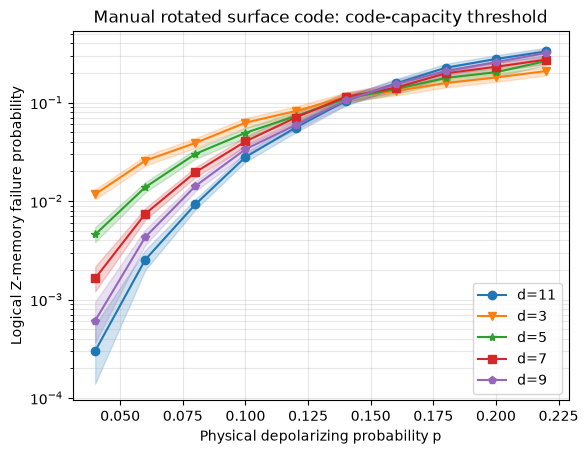

In [20]:
distances = [3, 5, 7, 9, 11]
noise_levels = [0.04, 0.06, 0.08, 0.10, 0.12, 0.14, 0.16, 0.18, 0.20, 0.22]

tasks = [
    
    sinter.Task(
        circuit=my_rotated_memory_z(distance=d, rounds=2, p=p),
        json_metadata={"d": d, "p": p},
    )
    for d in distances
    for p in noise_levels
]

stats = sinter.collect(
    num_workers=max(1, (os.cpu_count() or 2) - 1),
    tasks=tasks,
    decoders=["pymatching"],
    max_shots=100_000,
    max_errors=1_000,
    print_progress=True,
)

fig, ax = plt.subplots()
sinter.plot_error_rate(
    ax=ax,
    stats=stats,
    x_func=lambda s: s.json_metadata["p"],
    group_func=lambda s: f'd={s.json_metadata["d"]}',
)

ax.set(xlabel="Physical depolarizing probability p", ylabel="Logical Z-memory failure probability",
       title="Manual rotated surface code: code-capacity threshold")
ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

The estimated threshold is near $p=0.15$. 

This makes sense because
- We're running a logical Z memory experiment, so a physical X or Y error flips the Z-basis info, whereas a physical Z error does not.
- Thus, the effective bit-flip probabiltiy is p(X) + p(Y) = 2p/3. Then using the threshold for bit flip errors around 10%, 3/2*10%=15%.
- Also sanity check using the following:
- https://arxiv.org/pdf/0905.0531
- https://www.nature.com/articles/s42005-024-01883-4 reports 15% directly.

In [23]:
def my_rotated_memory_z_phenom(distance=3, p=0.0, rounds=2):

    """
    Rotated surface-code Z-memory experiment with phenomenological noise.

    Noise model:
    - DEPOLARIZE1(p) on every data qubit before each syndrome round.
    - X_ERROR(p) on every ancilla immediately before measurement.
    - Perfect state preparation, gates, and final data measurements.
    """

    # Input validation.
    if not isinstance(distance, int) or distance < 2:
        raise ValueError("distance must be an integer >= 2")

    if not isinstance(rounds, int) or rounds < 2:
        raise ValueError("rounds must be an integer >= 2")

    if not 0 <= p <= 1:
        raise ValueError("p must lie between 0 and 1")

    d = distance
    c = stim.Circuit()

    # ------------------------------------------------------------
    # 1. Qubit layout.
    # ------------------------------------------------------------

    data_xy = [(2*x+1, 2*y+1) for y in range(d) for x in range(d)]
    checks = []

    # Four-body bulk checks.
    for y in range(1, d):
        for x in range(1, d):
            checks.append(
                (2*x, 2*y, 'Z' if (x+y) % 2 == 0 else 'X')
            )

    # Two-body boundary checks.
    for x in range(1, d):
        if x % 2 == 1:
            checks.append((2*x, 0, 'X'))
        if x % 2 != d % 2:
            checks.append((2*x, 2*d, 'X'))

    for y in range(1, d):
        if y % 2 == 0:
            checks.append((0, 2*y, 'Z'))
        if y % 2 == d % 2:
            checks.append((2*d, 2*y, 'Z'))

    checks.sort(key=lambda t: (t[1], t[0]))

    coord_to_q = {}

    for q, xy in enumerate(
        data_xy + [(x, y) for x, y, _ in checks]
    ):
        coord_to_q[xy] = q
        c.append('QUBIT_COORDS', [q], list(xy))

    data = [coord_to_q[xy] for xy in data_xy]
    ancillas = [coord_to_q[(x, y)] for x, y, _ in checks]

    x_ancillas = [
        coord_to_q[(x, y)]
        for x, y, t in checks if t == 'X'
    ]

    z_check_indices = [
        i for i, (_, _, t) in enumerate(checks) if t == 'Z'
    ]

    # ------------------------------------------------------------
    # 2. CNOT scheduling.
    # ------------------------------------------------------------

    x_order = [(1, 1), (-1, 1), (1, -1), (-1, -1)]
    z_order = [(1, 1), (1, -1), (-1, 1), (-1, -1)]

    layers = [[] for _ in range(4)]

    for x, y, t in checks:
        a = coord_to_q[(x, y)]

        for k, (dx, dy) in enumerate(
            x_order if t == 'X' else z_order
        ):
            q = coord_to_q.get((x+dx, y+dy))

            if q is not None:
                layers[k].extend(
                    [a, q] if t == 'X' else [q, a]
                )

    # ------------------------------------------------------------
    # 3. Initialize physical qubits in |0>.
    # ------------------------------------------------------------

    c.append('R', data + ancillas)

    # ------------------------------------------------------------
    # 4. Repeated noisy syndrome measurement rounds.
    # ------------------------------------------------------------

    n = len(ancillas)

    for r in range(rounds):

        # Phenomenological data errors.
        # Independent X, Y, or Z errors before each round.
        c.append('TICK')
        c.append('DEPOLARIZE1', data, p)

        # Ideal stabilizer measurement circuit.
        c.append('TICK')
        c.append('H', x_ancillas)

        for layer in layers:
            c.append('TICK')
            if layer:
                c.append('CX', layer)

        c.append('TICK')
        c.append('H', x_ancillas)

        # Phenomenological measurement errors.
        # X_ERROR flips the ancilla's Z measurement outcome.
        c.append('TICK')
        c.append('X_ERROR', ancillas, p)
        c.append('MR', ancillas)

        # --------------------------------------------------------
        # 5. Detectors.
        # --------------------------------------------------------

        if r == 0:

            # Only Z checks are deterministic initially.
            for i in z_check_indices:
                x, y, _ = checks[i]

                c.append(
                    'DETECTOR',
                    [stim.target_rec(i-n)],
                    [x, y, 0]
                )

        else:

            # Compare each stabilizer outcome with the prior round.
            for i, (x, y, _) in enumerate(checks):

                c.append(
                    'DETECTOR',
                    [
                        stim.target_rec(i-n),
                        stim.target_rec(i-2*n)
                    ],
                    [x, y, r]
                )

    # ------------------------------------------------------------
    # 6. Perfect final Z-basis measurement of data.
    # ------------------------------------------------------------

    c.append('TICK')
    c.append('M', data)

    # ------------------------------------------------------------
    # 7. Final boundary detectors.
    # ------------------------------------------------------------

    data_i = {xy: i for i, xy in enumerate(data_xy)}

    for i in z_check_indices:
        x, y, _ = checks[i]

        parity = [
            stim.target_rec(data_i[(x+dx, y+dy)] - len(data))
            for dx in (-1, 1)
            for dy in (-1, 1)
            if (x+dx, y+dy) in data_i
        ]

        parity.append(
            stim.target_rec(i-n-len(data))
        )

        c.append(
            'DETECTOR',
            parity,
            [x, y, rounds]
        )

    # ------------------------------------------------------------
    # 8. Logical Z measurement.
    # ------------------------------------------------------------

    c.append(
        'OBSERVABLE_INCLUDE',
        [
            stim.target_rec(data_i[(2*x+1, 1)] - len(data))
            for x in range(d)
        ],
        0
    )

    return c


In [24]:

for d in [3, 5, 7, 9, 11]:

    ideal = my_rotated_memory_z_phenom(
        distance=d, p=0.0, rounds=d
    )

    expected_detectors = (
        2 * ((d*d - 1)//2)
        + (d-1) * (d*d - 1)
    )

    assert ideal.num_detectors == expected_detectors
    assert ideal.num_observables == 1

    det, obs = ideal.compile_detector_sampler().sample(
        shots=100,
        separate_observables=True
    )

    assert not det.any()
    assert not obs.any()

    noisy = my_rotated_memory_z_phenom(
        distance=d, p=0.03, rounds=d
    )

    dem = noisy.detector_error_model(
        decompose_errors=True
    )

    # Ensure the DEM agrees with the circuit's structure.
    assert dem.num_detectors == noisy.num_detectors
    assert dem.num_observables == 1

    # Ensure PyMatching can construct its decoding graph.
    matching = pymatching.Matching.from_detector_error_model(dem)

    print(
        f"d={d}: PASS | "
        f"{dem.num_detectors} detectors, "
        f"{dem.num_observables} observable(s)"
    )


d=3: PASS | 24 detectors, 1 observable(s)
d=5: PASS | 120 detectors, 1 observable(s)
d=7: PASS | 336 detectors, 1 observable(s)
d=9: PASS | 720 detectors, 1 observable(s)
d=11: PASS | 1320 detectors, 1 observable(s)


Starting 11 workers...
50 tasks left:
  workers    decoder eta shots_left errors_left json_metadata
        1 pymatching   ?     100000        1000 d=3,p=0.01   
        1 pymatching   ?     100000        1000 d=3,p=0.02   
        1 pymatching   ?     100000        1000 d=3,p=0.03   
        1 pymatching   ?     100000        1000 d=3,p=0.04   
        1 pymatching   ?     100000        1000 d=3,p=0.05   
        1 pymatching   ?     100000        1000 d=3,p=0.06   
        1 pymatching   ?     100000        1000 d=3,p=0.07   
        1 pymatching   ?     100000        1000 d=3,p=0.08   
        1 pymatching <1m      95631          35 d=3,p=0.09   
        1 pymatching   ?     100000        1000 d=3,p=0.1    
        1 pymatching   ?     100000        1000 d=5,p=0.01   
        0 pymatching ?·∞     100000        1000 d=5,p=0.02   
        0 pymatching ?·∞     100000        1000 d=5,p=0.03   
        0 pymatching ?·∞     100000        1000 d=5,p=0.04   
        0 pymatching ?·∞     100

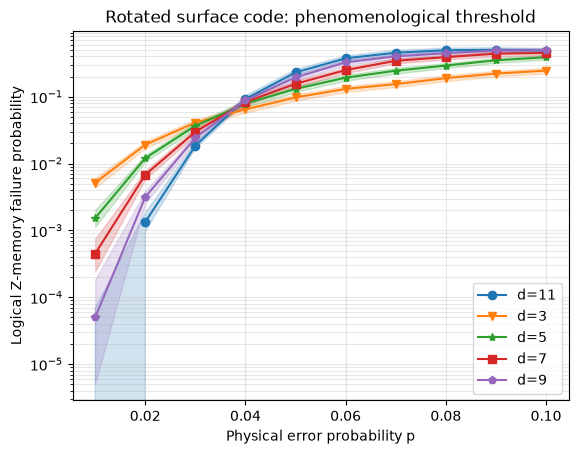

In [25]:

# Physical noise probabilities to test.
distances = [3, 5, 7, 9, 11]

noise_levels = [
    0.01, 0.02, 0.03, 0.04, 0.05,
    0.06, 0.07, 0.08, 0.09, 0.10
]

# Create simulation tasks.
tasks_phenom = [

    sinter.Task(
        circuit=my_rotated_memory_z_phenom(
            distance=d,
            rounds=d,
            p=p
        ),
        json_metadata={"d": d, "p": p},
    )

    for d in distances
    for p in noise_levels
]

# Run Monte Carlo simulations using PyMatching.
stats_phenom = sinter.collect(
    num_workers=max(1, (os.cpu_count() or 2) - 1),
    tasks=tasks_phenom,
    decoders=["pymatching"],
    max_shots=100_000,
    max_errors=1_000,
    print_progress=True,
)

# Plot logical error rate versus physical error probability.
fig, ax = plt.subplots()

sinter.plot_error_rate(
    ax=ax,
    stats=stats_phenom,
    x_func=lambda s: s.json_metadata["p"],
    group_func=lambda s: f'd={s.json_metadata["d"]}',
)

ax.set(
    xlabel="Physical error probability p",
    ylabel="Logical Z-memory failure probability",
    title="Rotated surface code: phenomenological threshold"
)

ax.set_yscale("log")
ax.grid(True, which="both", alpha=0.3)
ax.legend()

plt.show()